# 06 · Modelo v4 — scale_pos_weight agresivo + experimento baja1

## Cambios respecto a v3

### Experimento B — scale_pos_weight agresivo
En v3 Optuna encontró `scale_pos_weight=223` (ratio natural=158). Lo empujamos más:
exploramos valores entre 300 y 600 para forzar al modelo a ser más agresivo
detectando positivos. Justificación: ratio de ganancia real es 39:1 pero el
dataset tiene 158:1 negativos — el modelo es más conservador de lo que necesitamos.

### Experimento C — baja1 como positivo
Entrenamos una variante donde `baja1` se trata como target=1 (igual que baja2).
La función de ganancia para evaluar sigue siendo la original (baja2 = TP, resto = FP).
Si captura mejor el perfil de los FN ricos → adoptamos. Si no → descartamos.

### Visualización del corte óptimo
Gráfico explícito de ganancia vs N clientes intervenidos para elegir el corte
del semillerio con criterio visual claro.

---
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 6 — Modelado v4  
**Última actualización:** 2026-10

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install optuna lightgbm --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.1 MB/s eta 0:00:00


In [3]:
import gc
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
import optuna
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE  = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP  = RUTA_BASE / 'Competencia 1'
RUTA_SUBS  = RUTA_COMP / 'submissions1'     # nueva carpeta
RUTA_SUBS.mkdir(parents=True, exist_ok=True)

CKPT_B     = RUTA_COMP / 'dataset_fe_v3.parquet'         # reutilizamos el FE de v3
CKPT_C_V3  = RUTA_COMP / 'mejores_params_optuna_v3.json' # params v3 como base
CKPT_C_V4  = RUTA_COMP / 'mejores_params_optuna_v4.json' # params v4 (nuevo)
ARCHIVO_METRICAS = RUTA_COMP / 'metricas_experimentos.csv'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'
TARGET      = 'es_baja2'

MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108

GANANCIA_TP =  1_072_500
COSTO_FP    =    -27_500
SEED        = 42

def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

print('Checkpoints:')
for ck in [CKPT_B, CKPT_C_V3, CKPT_C_V4]:
    print(f'  {ck.name}: {"✓ existe" if ck.exists() else "✗ pendiente"}')
print(f'Submissions: {RUTA_SUBS}')

Checkpoints:
  dataset_fe_v3.parquet: ✓ existe
  mejores_params_optuna_v3.json: ✓ existe
  mejores_params_optuna_v4.json: ✗ pendiente
Submissions: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions1


## 1 · Funciones de ganancia

In [4]:
def ganancia_por_threshold(y_true, y_prob, n=500):
    thresholds = np.linspace(0.001, 0.999, n)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp = ((y_true == 1) & (pred == 1)).sum()
        fp = ((y_true == 0) & (pred == 1)).sum()
        rows.append({'threshold': t,
                     'ganancia': tp * GANANCIA_TP + fp * COSTO_FP,
                     'tp': int(tp), 'fp': int(fp),
                     'n_intervenidos': int(tp + fp)})
    return pd.DataFrame(rows)

def threshold_optimo(y_true, y_prob):
    df_t = ganancia_por_threshold(y_true, y_prob)
    return df_t.loc[df_t['ganancia'].idxmax()].to_dict()


def plot_ganancia_completo(y_true, y_prob, titulo='', fold_ref=None):
    """
    Gráfico triple:
    1. Ganancia vs threshold
    2. Ganancia vs N intervenidos  ← el más útil para elegir el corte del semillerio
    3. TP y FP vs N intervenidos
    Muestra claramente el óptimo y cuántos clientes corresponde intervenir.
    """
    df_t = ganancia_por_threshold(y_true, y_prob)
    opt  = df_t.loc[df_t['ganancia'].idxmax()].to_dict()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # ── Gráfico 1: Ganancia vs Threshold ─────────────────────────────────────
    ax = axes[0]
    ax.plot(df_t['threshold'], df_t['ganancia'] / 1e9, color='#4C72B0', lw=2)
    ax.axvline(opt['threshold'], color='#C44E52', ls='--', lw=1.8,
               label=f"Óptimo: {opt['threshold']:.4f}")
    ax.axhline(0, color='gray', ls=':', lw=1)
    ax.set_title(f'Ganancia vs Threshold\n{titulo}', fontweight='bold')
    ax.set_xlabel('Threshold de probabilidad')
    ax.set_ylabel('Ganancia ($B)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
    ax.legend(fontsize=9)

    # ── Gráfico 2: Ganancia vs N intervenidos ─────────────────────────────────
    # Este es el más directo para elegir el corte del semillerio
    ax = axes[1]
    # Ordenamos por n_intervenidos para que la curva sea suave
    df_sorted = df_t.sort_values('n_intervenidos')
    ax.plot(df_sorted['n_intervenidos'], df_sorted['ganancia'] / 1e9,
            color='#4C72B0', lw=2)
    ax.axvline(opt['n_intervenidos'], color='#C44E52', ls='--', lw=1.8,
               label=f"Óptimo: {opt['n_intervenidos']:,.0f} clientes")
    ax.axhline(0, color='gray', ls=':', lw=1)

    # Zona del semillerio: ±10% del óptimo
    n_opt = opt['n_intervenidos']
    ax.axvspan(n_opt * 0.90, n_opt * 1.10,
               alpha=0.12, color='#C44E52', label='Zona ±10% del óptimo')

    # Si hay referencia de otro fold
    if fold_ref is not None:
        ax.axvline(fold_ref, color='#55A868', ls=':', lw=1.5,
                   label=f'Ref. fold anterior: {fold_ref:,.0f}')

    ax.set_title(f'Ganancia vs N clientes a intervenir\n{titulo}', fontweight='bold')
    ax.set_xlabel('N clientes intervenidos')
    ax.set_ylabel('Ganancia ($B)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    ax.legend(fontsize=8)

    # ── Gráfico 3: TP y FP vs N intervenidos ─────────────────────────────────
    ax = axes[2]
    ax2 = ax.twinx()
    l1, = ax.plot(df_sorted['n_intervenidos'], df_sorted['tp'],
                  color='#55A868', lw=2, label='TP (baja2 detectados)')
    l2, = ax2.plot(df_sorted['n_intervenidos'], df_sorted['fp'],
                   color='#DD8452', lw=2, ls='--', label='FP (intervención en vano)')
    ax.axvline(opt['n_intervenidos'], color='#C44E52', ls='--', lw=1.5)
    ax.set_title(f'TP y FP vs N intervenidos\n{titulo}', fontweight='bold')
    ax.set_xlabel('N clientes intervenidos')
    ax.set_ylabel('TP', color='#55A868')
    ax2.set_ylabel('FP', color='#DD8452')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    lines = [l1, l2]
    ax.legend(lines, [l.get_label() for l in lines], fontsize=8)

    plt.tight_layout()
    plt.show()

    print(f"  Threshold óptimo:      {opt['threshold']:.5f}")
    print(f"  Ganancia:              ${opt['ganancia']:>15,.0f}")
    print(f"  N clientes a intervenir: {opt['n_intervenidos']:,.0f}  ← usar como centro del semillerio")
    print(f"  TP detectados:         {opt['tp']:,}")
    print(f"  FP (en vano):          {opt['fp']:,}")
    print(f"  Zona semillerio sugerida: [{int(n_opt*0.95):,} — {int(n_opt*1.05):,}]")
    return opt

print('✓ Funciones de ganancia listas.')

✓ Funciones de ganancia listas.


## 2 · Carga de datos

In [5]:
print('Cargando dataset_fe_v3.parquet...')
df = pd.read_parquet(CKPT_B)
df = df.sort_values([COL_ID, COL_PERIODO]).reset_index(drop=True)
print(f'  {df.shape[0]:,} filas × {df.shape[1]} columnas — {mem_mb(df):.1f} MB')

EXCLUIR = {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}
FEATURE_COLS = [c for c in df.columns if c not in EXCLUIR]

# Ratio natural de desbalance
mask_entren = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
y_ref = df.loc[mask_entren, TARGET]
SCALE_NATURAL = float((y_ref == 0).sum() / (y_ref == 1).sum())
del y_ref; gc.collect()

print(f'Features: {len(FEATURE_COLS)}')
print(f'scale_pos_weight natural: {SCALE_NATURAL:.1f}')
print(f'  v3 Optuna encontró:     223  (1.4x el natural)')
print(f'  v4 vamos a explorar:    300-600 (2x-4x el natural)')

FOLDS = [
    {'nombre': 'fold_2', 'train': [202103],                 'test': 202104},
    {'nombre': 'fold_3', 'train': [202103, 202104],         'test': 202105},
    {'nombre': 'fold_4', 'train': [202103, 202104, 202105], 'test': 202106},
]

def get_split(meses_train, mes_test, target_col=TARGET):
    mt = df[COL_PERIODO].isin(meses_train) & df[target_col].notna()
    me = (df[COL_PERIODO] == mes_test)      & df[target_col].notna()
    return (df.loc[mt, FEATURE_COLS], df.loc[mt, target_col].astype(int),
            df.loc[me, FEATURE_COLS], df.loc[me, target_col].astype(int))

Cargando dataset_fe_v3.parquet...
  983,061 filas × 327 columnas — 1041.6 MB
Features: 323
scale_pos_weight natural: 158.8
  v3 Optuna encontró:     223  (1.4x el natural)
  v4 vamos a explorar:    300-600 (2x-4x el natural)


## 3 · Experimento B — Optuna con scale_pos_weight agresivo

Forzamos el rango de `scale_pos_weight` entre 2x y 5x el ratio natural.
El resto de hiperparámetros se optimizan normalmente.
Partimos de los mejores params de v3 como referencia.

In [6]:
# Cargamos params v3 como referencia
with open(CKPT_C_V3) as f:
    params_v3 = json.load(f)

print('Params v3 de referencia:')
for k, v in params_v3.items():
    if k not in {'ganancia_optuna_fold4', 'auc_fold4', 'n_trials', 'fecha'}:
        print(f'  {k}: {v}')

Params v3 de referencia:
  num_leaves: 24
  max_depth: 5
  learning_rate: 0.025832729613126503
  n_estimators: 950
  min_child_samples: 168
  feature_fraction: 0.6386999057405924
  bagging_fraction: 0.4270280340719993
  bagging_freq: 4
  reg_alpha: 0.0014826385435596646
  reg_lambda: 0.5480606961681793
  scale_pos_weight: 223.3988606436954


In [7]:
if CKPT_C_V4.exists():
    print('✓ CKPT_C_V4 encontrado — cargando params v4...')
    with open(CKPT_C_V4) as f:
        params_guardados_v4 = json.load(f)
    PARAMS_OPT_B = {k: v for k, v in params_guardados_v4.items()
                    if k not in {'ganancia_optuna_fold4', 'auc_fold4',
                                 'n_trials', 'fecha', 'experimento'}}
    PARAMS_OPT_B.update({'objective': 'binary', 'metric': 'binary_logloss',
                          'boosting_type': 'gbdt', 'verbosity': -1,
                          'n_jobs': -1, 'random_state': SEED})
    print(f'  Ganancia Optuna v4 (fold4): ${params_guardados_v4["ganancia_optuna_fold4"]:,.0f}')
    print('  → Saltá a la sección 4.')
else:
    print('✗ CKPT_C_V4 no encontrado — ejecutar Optuna v4.')

✗ CKPT_C_V4 no encontrado — ejecutar Optuna v4.


In [8]:
# ── Solo si CKPT_C_V4 no existe ───────────────────────────────────────────────
if not CKPT_C_V4.exists():

    Xtr_opt, ytr_opt, Xte_opt, yte_opt = get_split([202103, 202104, 202105], 202106)
    yte_opt_arr = yte_opt.values

    def objective_v4(trial):
        params = {
            'objective': 'binary', 'metric': 'binary_logloss',
            'boosting_type': 'gbdt', 'verbosity': -1,
            'n_jobs': -1, 'random_state': SEED,
            # Arquitectura — mismos rangos que v3
            'num_leaves':        trial.suggest_int('num_leaves', 16, 256),
            'max_depth':         trial.suggest_int('max_depth', 4, 12),
            'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'n_estimators':      trial.suggest_int('n_estimators', 100, 1000, step=50),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 300),
            'feature_fraction':  trial.suggest_float('feature_fraction', 0.4, 1.0),
            'bagging_fraction':  trial.suggest_float('bagging_fraction', 0.4, 1.0),
            'bagging_freq':      trial.suggest_int('bagging_freq', 1, 7),
            'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
            # ── KEY: scale_pos_weight forzado a zona agresiva ─────────────────
            # v3 Optuna encontró 223 (1.4x natural)
            # v4: exploramos 2x a 5x el natural → 316 a 790
            'scale_pos_weight': trial.suggest_float(
                'scale_pos_weight',
                SCALE_NATURAL * 2.0,
                SCALE_NATURAL * 5.0
            ),
        }
        model = lgb.LGBMClassifier(**params)
        model.fit(Xtr_opt, ytr_opt,
                  eval_set=[(Xte_opt, yte_opt)],
                  callbacks=[lgb.early_stopping(30, verbose=False),
                             lgb.log_evaluation(-1)])
        prob = model.predict_proba(Xte_opt)[:, 1]
        del model; gc.collect()
        return threshold_optimo(yte_opt_arr, prob)['ganancia']

    N_TRIALS = 50
    study_b = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED),
        study_name='lgbm_churn_v4_expB'
    )
    # Warm start: agregamos los mejores params de v3 como primer trial
    params_v3_clean = {k: v for k, v in params_v3.items()
                       if k not in {'ganancia_optuna_fold4', 'auc_fold4',
                                    'n_trials', 'fecha'}}
    # Ajustamos scale_pos_weight al rango válido del experimento B
    params_v3_clean['scale_pos_weight'] = max(
        SCALE_NATURAL * 2.0,
        min(SCALE_NATURAL * 5.0, params_v3_clean.get('scale_pos_weight', SCALE_NATURAL * 2))
    )
    study_b.enqueue_trial(params_v3_clean)

    study_b.optimize(objective_v4, n_trials=N_TRIALS, show_progress_bar=True)

    del Xtr_opt, ytr_opt, Xte_opt; gc.collect()

    print(f'\n✓ Optuna v4 completado — {N_TRIALS} trials')
    print(f'Mejor ganancia: ${study_b.best_value:,.0f}')
    print('Mejores parámetros:')
    for k, v in study_b.best_params.items():
        print(f'  {k}: {v}')

    PARAMS_OPT_B = {
        'objective': 'binary', 'metric': 'binary_logloss',
        'boosting_type': 'gbdt', 'verbosity': -1,
        'n_jobs': -1, 'random_state': SEED,
        **study_b.best_params
    }

    guardar = {**study_b.best_params,
               'ganancia_optuna_fold4': study_b.best_value,
               'n_trials': N_TRIALS,
               'experimento': 'B_scale_pos_weight_agresivo',
               'fecha': datetime.now().isoformat()}
    with open(CKPT_C_V4, 'w') as f:
        json.dump(guardar, f, indent=2)
    print(f'✓ CKPT_C_V4 guardado')

  0%|          | 0/50 [00:00<?, ?it/s]


✓ Optuna v4 completado — 50 trials
Mejor ganancia: $380,050,000
Mejores parámetros:
  num_leaves: 29
  max_depth: 5
  learning_rate: 0.012770299030719962
  n_estimators: 850
  min_child_samples: 135
  feature_fraction: 0.5461399980545687
  bagging_fraction: 0.4666681892559699
  bagging_freq: 3
  reg_alpha: 4.344152598110105
  reg_lambda: 0.06276545259160875
  scale_pos_weight: 490.68675674701177
✓ CKPT_C_V4 guardado


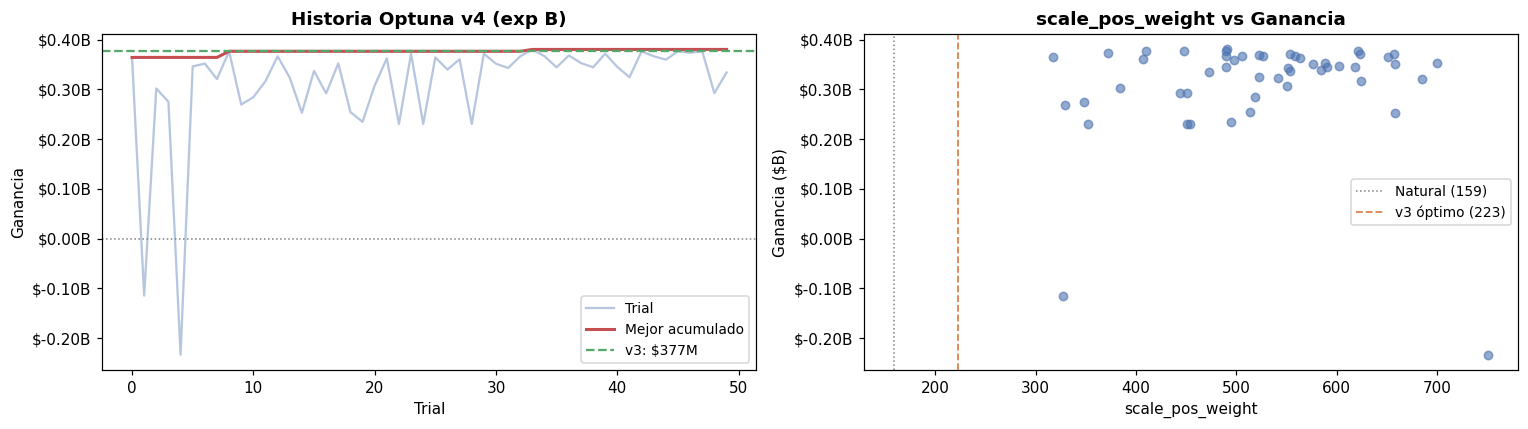

In [9]:
# Gráficos Optuna (solo si corrió en esta sesión)
if 'study_b' in dir():
    valores   = [t.value for t in study_b.trials if t.value is not None]
    mejor_acc = pd.Series(valores).cummax()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ax = axes[0]
    ax.plot(valores, alpha=0.4, color='#4C72B0', label='Trial')
    ax.plot(mejor_acc, color='#C44E52', lw=2, label='Mejor acumulado')
    ax.axhline(377_685_000, color='#55A868', ls='--', lw=1.5,
               label='v3: $377M')
    ax.axhline(0, color='gray', ls=':', lw=1)
    ax.set_title('Historia Optuna v4 (exp B)', fontweight='bold')
    ax.set_xlabel('Trial')
    ax.set_ylabel('Ganancia')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e9:.2f}B'))
    ax.legend(fontsize=9)

    ax = axes[1]
    # Scatter: scale_pos_weight vs ganancia
    spw_vals = [t.params.get('scale_pos_weight', None) for t in study_b.trials
                if t.value is not None]
    g_vals   = [t.value for t in study_b.trials if t.value is not None]
    ax.scatter(spw_vals, [g/1e9 for g in g_vals],
               alpha=0.6, color='#4C72B0', s=30)
    ax.axvline(SCALE_NATURAL, color='gray', ls=':', lw=1, label=f'Natural ({SCALE_NATURAL:.0f})')
    ax.axvline(223, color='#DD8452', ls='--', lw=1.2, label='v3 óptimo (223)')
    ax.set_title('scale_pos_weight vs Ganancia', fontweight='bold')
    ax.set_xlabel('scale_pos_weight')
    ax.set_ylabel('Ganancia ($B)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print('(Gráficos Optuna disponibles solo si corrió en esta sesión)')

## 4 · Walk-forward Experimento B


  FOLD_2 — test: 202104 [Exp B]
AUC: 0.8540


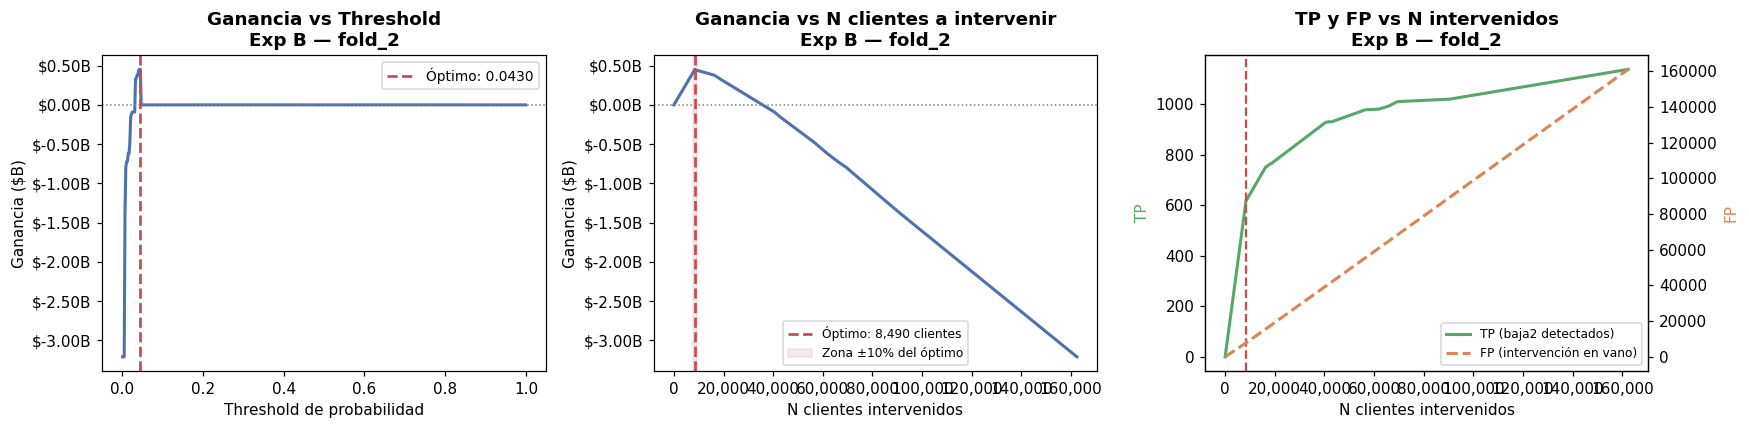

  Threshold óptimo:      0.04300
  Ganancia:              $    452,925,000
  N clientes a intervenir: 8,490  ← usar como centro del semillerio
  TP detectados:         624.0
  FP (en vano):          7,866.0
  Zona semillerio sugerida: [8,065 — 8,914]

  FOLD_3 — test: 202105 [Exp B]
AUC: 0.8451


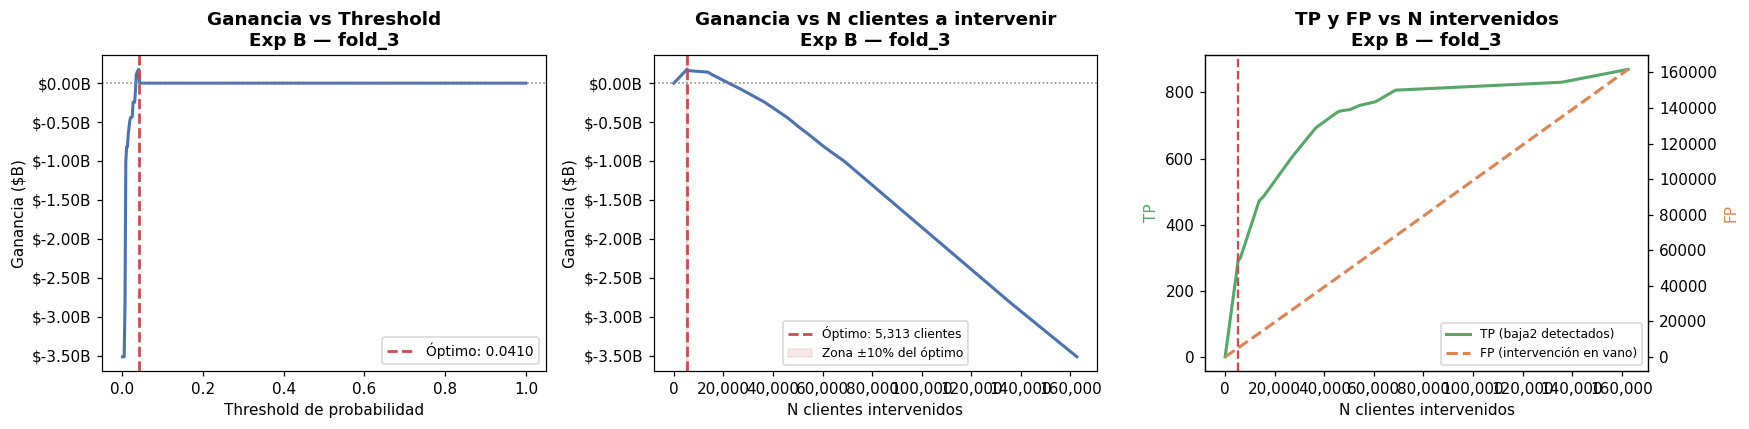

  Threshold óptimo:      0.04100
  Ganancia:              $    177,292,500
  N clientes a intervenir: 5,313  ← usar como centro del semillerio
  TP detectados:         294.0
  FP (en vano):          5,019.0
  Zona semillerio sugerida: [5,047 — 5,578]

  FOLD_4 — test: 202106 [Exp B]
AUC: 0.8665


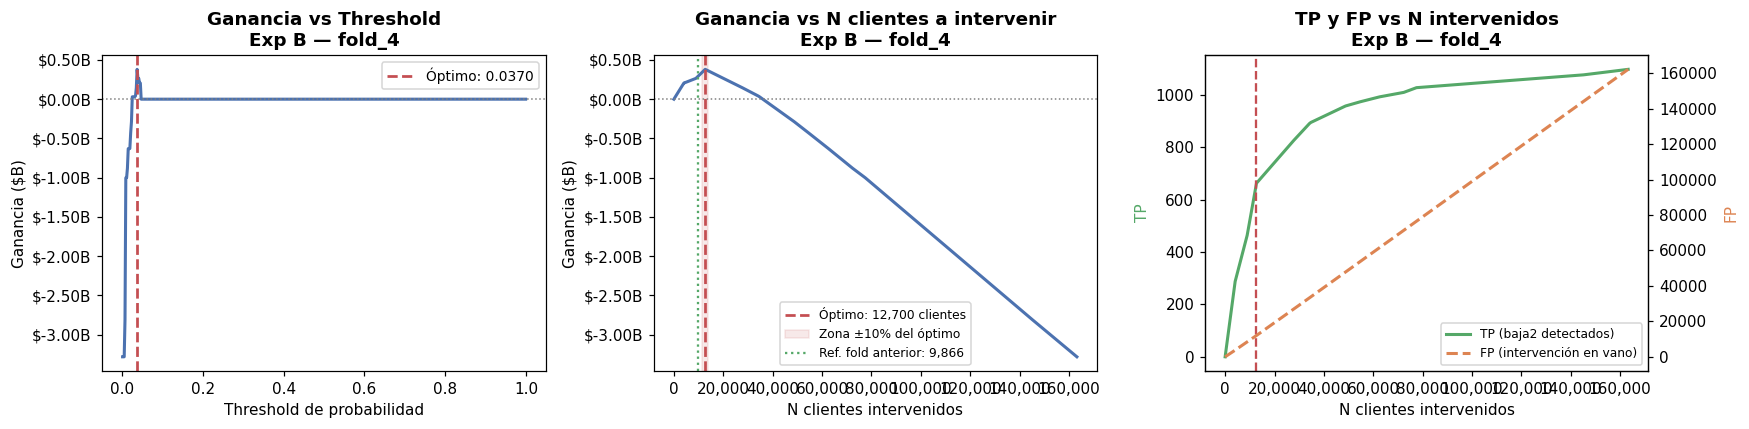

  Threshold óptimo:      0.03700
  Ganancia:              $    380,050,000
  N clientes a intervenir: 12,700  ← usar como centro del semillerio
  TP detectados:         663.0
  FP (en vano):          12,037.0
  Zona semillerio sugerida: [12,065 — 13,335]

RESUMEN EXP B
  fold    auc    ganancia  threshold_opt  n_intervenidos
fold_2 0.8540 452925000.0          0.043          8490.0
fold_3 0.8451 177292500.0          0.041          5313.0
fold_4 0.8665 380050000.0          0.037         12700.0

--- vs v3 ---
  fold_2: +$57,942,500
  fold_3: $-14,795,000
  fold_4: +$2,365,000


In [10]:
resultados_b = []
n_opt_fold4_b = None  # para usar como centro del semillerio

for fold in FOLDS:
    print(f"\n{'='*55}")
    print(f"  {fold['nombre'].upper()} — test: {fold['test']} [Exp B]")
    print('='*55)

    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    modelo = lgb.LGBMClassifier(**PARAMS_OPT_B)
    modelo.fit(Xtr, ytr,
               eval_set=[(Xte, yte)],
               callbacks=[lgb.early_stopping(50, verbose=False),
                          lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    auc  = roc_auc_score(yte, prob)
    print(f'AUC: {auc:.4f}')

    # Gráfico triple de ganancia
    opt = plot_ganancia_completo(
        yte.values, prob,
        titulo=f"Exp B — {fold['nombre']}",
        fold_ref=9866 if fold['nombre'] == 'fold_4' else None
    )

    if fold['nombre'] == 'fold_4':
        n_opt_fold4_b = opt['n_intervenidos']

    resultados_b.append({
        'fold': fold['nombre'], 'mes_test': fold['test'],
        'experimento': 'B', 'auc': round(auc, 4),
        'ganancia': opt['ganancia'],
        'threshold_opt': opt['threshold'],
        'tp': opt['tp'], 'fp': opt['fp'],
        'n_intervenidos': opt['n_intervenidos'],
    })
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

df_b = pd.DataFrame(resultados_b)
print(f"\n{'='*55}\nRESUMEN EXP B\n{'='*55}")
print(df_b[['fold','auc','ganancia','threshold_opt','n_intervenidos']].to_string(index=False))
print(f'\n--- vs v3 ---')
v3 = {'fold_2': 394_982_500, 'fold_3': 192_087_500, 'fold_4': 377_685_000}
for _, row in df_b.iterrows():
    diff = row['ganancia'] - v3.get(row['fold'], 0)
    print(f"  {row['fold']}: {'+' if diff>=0 else ''}${diff:,.0f}")

## 5 · Experimento C — baja1 como positivo

Construimos un target alternativo donde `baja1` = 1 (igual que `baja2`).
**La evaluación sigue usando la función de ganancia original** (solo baja2 = TP real).
Si mejora → el perfil de baja1 ayuda a capturar los FN difíciles.
Si no mejora → confirmamos que excluir baja1 es lo correcto.

In [11]:
# Construimos target_c: baja1 y baja2 = 1, continua = 0
TARGET_C = 'es_baja_any'
df[TARGET_C] = np.nan

mask_entren = df[COL_PERIODO].isin(MESES_CON_TARGET)
df.loc[mask_entren & (df[TARGET_RAW] == 'baja2'),    TARGET_C] = 1.0
df.loc[mask_entren & (df[TARGET_RAW] == 'baja1'),    TARGET_C] = 1.0
df.loc[mask_entren & (df[TARGET_RAW] == 'continua'), TARGET_C] = 0.0

# Verificamos
for mes in MESES_CON_TARGET:
    sub = df[df[COL_PERIODO] == mes]
    n1 = (sub[TARGET_C] == 1).sum()
    n0 = (sub[TARGET_C] == 0).sum()
    print(f'  {mes}: positivos={n1} ({n1/(n1+n0)*100:.2f}%) | negativos={n0}')

# Ratio de desbalance para el experimento C
mask_c = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET_C].notna()
y_c = df.loc[mask_c, TARGET_C]
SCALE_C = float((y_c == 0).sum() / (y_c == 1).sum())
print(f'\nscale_pos_weight para exp C: {SCALE_C:.1f} (baja1+baja2 como positivos)')
del y_c; gc.collect()

  202103: positivos=1979 (1.21%) | negativos=160921
  202104: positivos=2103 (1.29%) | negativos=161181
  202105: positivos=2013 (1.23%) | negativos=161755
  202106: positivos=1972 (1.20%) | negativos=162142

scale_pos_weight para exp C: 80.1 (baja1+baja2 como positivos)


0


  FOLD_2 — test: 202104 [Exp C]
AUC (vs baja2 real): 0.8743


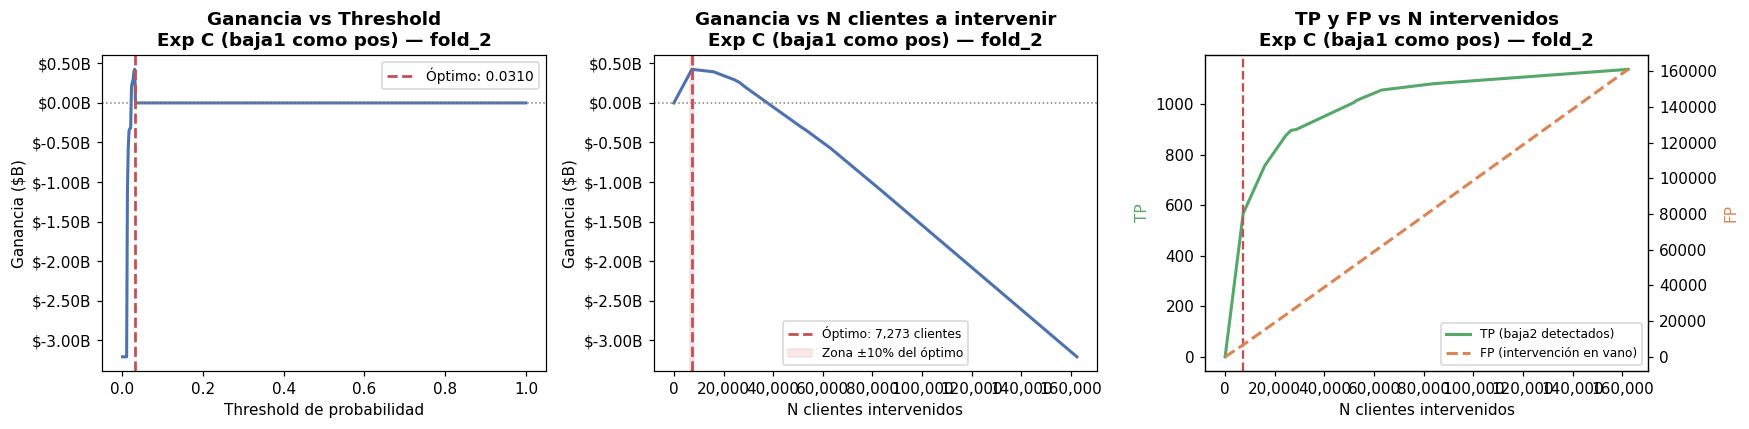

  Threshold óptimo:      0.03100
  Ganancia:              $    424,792,500
  N clientes a intervenir: 7,273  ← usar como centro del semillerio
  TP detectados:         568.0
  FP (en vano):          6,705.0
  Zona semillerio sugerida: [6,909 — 7,636]

  FOLD_3 — test: 202105 [Exp C]
AUC (vs baja2 real): 0.8523


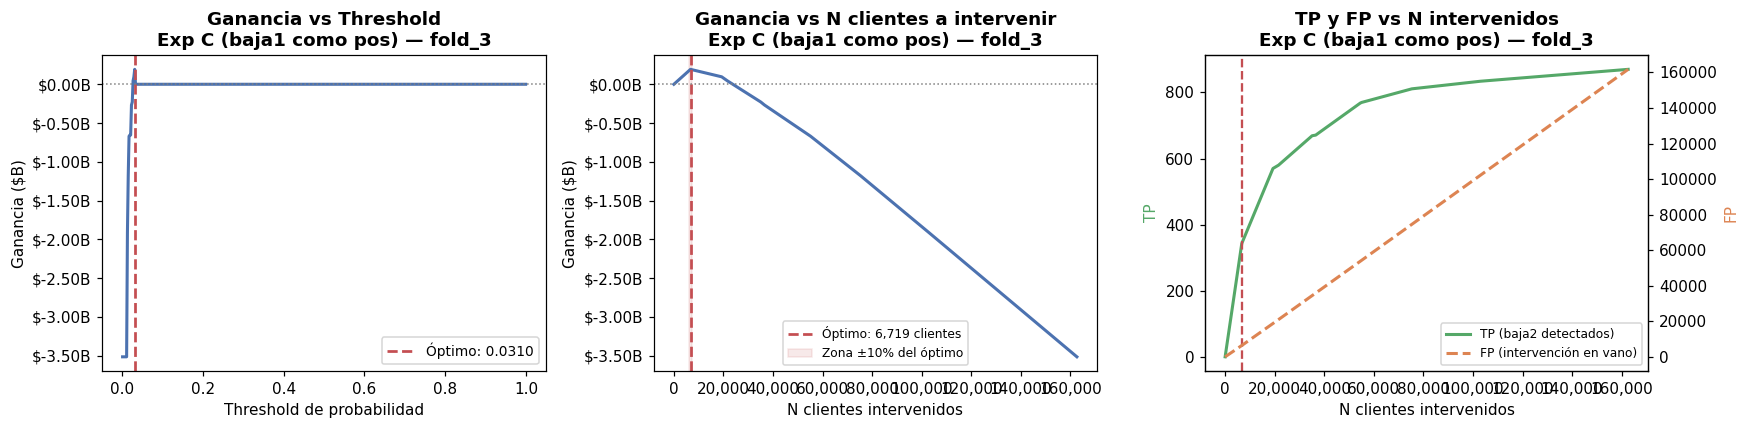

  Threshold óptimo:      0.03100
  Ganancia:              $    192,527,500
  N clientes a intervenir: 6,719  ← usar como centro del semillerio
  TP detectados:         343.0
  FP (en vano):          6,376.0
  Zona semillerio sugerida: [6,383 — 7,054]

  FOLD_4 — test: 202106 [Exp C]
AUC (vs baja2 real): 0.8689


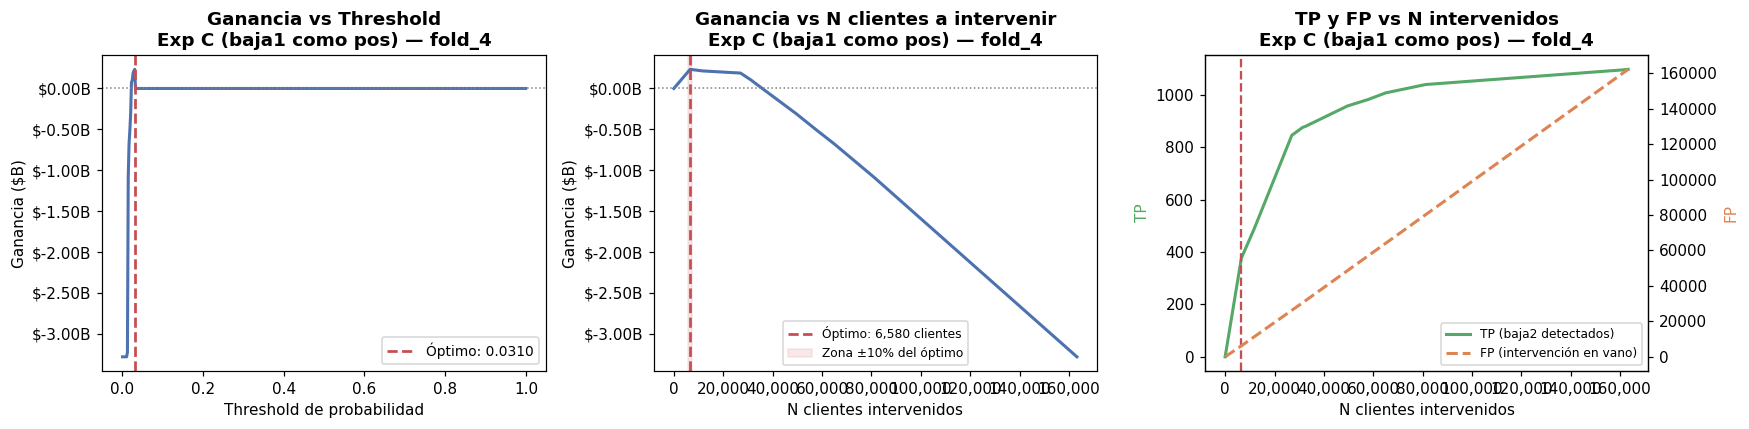

  Threshold óptimo:      0.03100
  Ganancia:              $    233,750,000
  N clientes a intervenir: 6,580  ← usar como centro del semillerio
  TP detectados:         377.0
  FP (en vano):          6,203.0
  Zona semillerio sugerida: [6,251 — 6,909]

RESUMEN EXP C
  fold    auc    ganancia  threshold_opt  n_intervenidos
fold_2 0.8743 424792500.0          0.031          7273.0
fold_3 0.8523 192527500.0          0.031          6719.0
fold_4 0.8689 233750000.0          0.031          6580.0


In [12]:
# Usamos los mismos params de Exp B pero con el nuevo target
# scale_pos_weight lo ajustamos al nuevo ratio
PARAMS_C = {**PARAMS_OPT_B, 'scale_pos_weight': SCALE_C * 2.0}

resultados_c = []
n_opt_fold4_c = None

for fold in FOLDS:
    print(f"\n{'='*55}")
    print(f"  {fold['nombre'].upper()} — test: {fold['test']} [Exp C]")
    print('='*55)

    # Train con target_c (baja1+baja2=1)
    # Test evaluado con TARGET original (solo baja2=1)
    mt_c = df[COL_PERIODO].isin(fold['train']) & df[TARGET_C].notna()
    me   = (df[COL_PERIODO] == fold['test'])   & df[TARGET].notna()

    Xtr = df.loc[mt_c, FEATURE_COLS]
    ytr = df.loc[mt_c, TARGET_C].astype(int)    # train con baja1+baja2
    Xte = df.loc[me,   FEATURE_COLS]
    yte = df.loc[me,   TARGET].astype(int)       # evaluar solo baja2

    modelo = lgb.LGBMClassifier(**PARAMS_C)
    modelo.fit(Xtr, ytr,
               eval_set=[(Xte, yte)],
               callbacks=[lgb.early_stopping(50, verbose=False),
                          lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    auc  = roc_auc_score(yte, prob)
    print(f'AUC (vs baja2 real): {auc:.4f}')

    opt = plot_ganancia_completo(
        yte.values, prob,
        titulo=f"Exp C (baja1 como pos) — {fold['nombre']}"
    )

    if fold['nombre'] == 'fold_4':
        n_opt_fold4_c = opt['n_intervenidos']

    resultados_c.append({
        'fold': fold['nombre'], 'mes_test': fold['test'],
        'experimento': 'C', 'auc': round(auc, 4),
        'ganancia': opt['ganancia'],
        'threshold_opt': opt['threshold'],
        'tp': opt['tp'], 'fp': opt['fp'],
        'n_intervenidos': opt['n_intervenidos'],
    })
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

df_c = pd.DataFrame(resultados_c)
print(f"\n{'='*55}\nRESUMEN EXP C\n{'='*55}")
print(df_c[['fold','auc','ganancia','threshold_opt','n_intervenidos']].to_string(index=False))

## 6 · Comparativa B vs C vs v3

COMPARATIVA COMPLETA — Ganancia por fold y experimento
         |              v3 |           Exp B |           Exp C |      B vs v3 |      C vs v3
─────────────────────────────────────────────────────────────────────────────────────
  fold_2 | $  394,982,500 | $  452,925,000 | $  424,792,500 | ++57.9M | ++29.8M
  fold_3 | $  192,087,500 | $  177,292,500 | $  192,527,500 | -14.8M | ++0.4M
  fold_4 | $  377,685,000 | $  380,050,000 | $  233,750,000 | ++2.4M | -143.9M


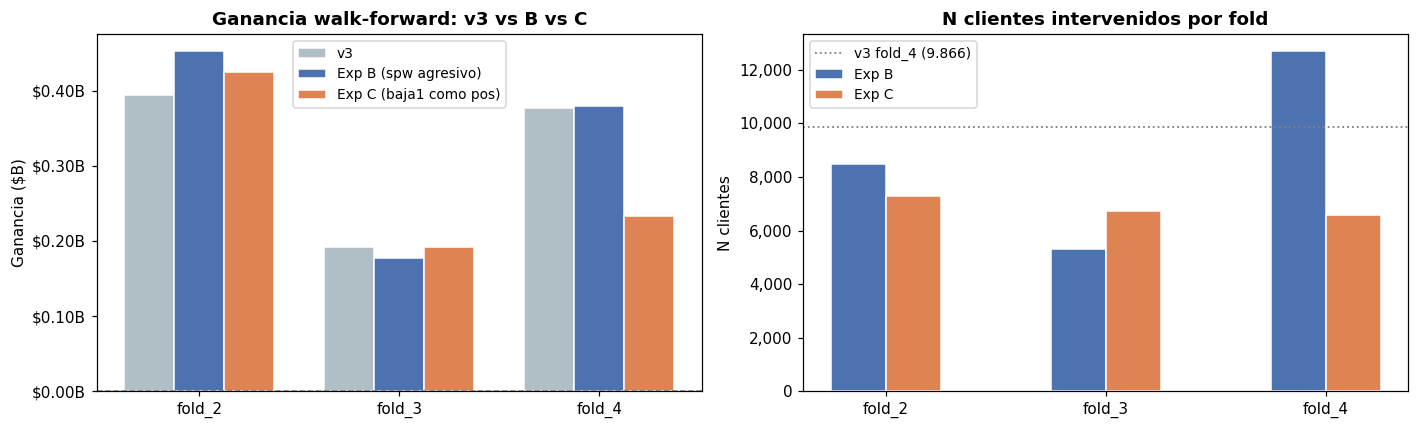


→ Experimento ganador en fold_4: B
  Exp B fold_4: $380,050,000
  Exp C fold_4: $233,750,000

→ Usar params del Exp B para el semillerio de submission


In [13]:
# Tabla comparativa
todos = pd.concat([df_b, df_c], ignore_index=True)
v3_vals = {'fold_2': 394_982_500, 'fold_3': 192_087_500, 'fold_4': 377_685_000}

print('COMPARATIVA COMPLETA — Ganancia por fold y experimento')
print(f'{"":>8} | {"v3":>15} | {"Exp B":>15} | {"Exp C":>15} | {"B vs v3":>12} | {"C vs v3":>12}')
print('─' * 85)
for fold_nombre in ['fold_2', 'fold_3', 'fold_4']:
    g_v3 = v3_vals[fold_nombre]
    g_b  = df_b[df_b['fold'] == fold_nombre]['ganancia'].values[0]
    g_c  = df_c[df_c['fold'] == fold_nombre]['ganancia'].values[0]
    diff_b = g_b - g_v3
    diff_c = g_c - g_v3
    print(f'{fold_nombre:>8} | ${g_v3:>13,.0f} | ${g_b:>13,.0f} | ${g_c:>13,.0f} | '
          f'{"+" if diff_b>=0 else ""}{diff_b/1e6:>+.1f}M | '
          f'{"+" if diff_c>=0 else ""}{diff_c/1e6:>+.1f}M')

# Visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
folds_labels = ['fold_2', 'fold_3', 'fold_4']
x = np.arange(len(folds_labels))
w = 0.25

ax = axes[0]
ax.bar(x - w, [v3_vals[f]/1e9 for f in folds_labels], w,
       label='v3', color='#B0BEC5', edgecolor='white')
ax.bar(x,     df_b['ganancia']/1e9, w,
       label='Exp B (spw agresivo)', color='#4C72B0', edgecolor='white')
ax.bar(x + w, df_c['ganancia']/1e9, w,
       label='Exp C (baja1 como pos)', color='#DD8452', edgecolor='white')
ax.set_title('Ganancia walk-forward: v3 vs B vs C', fontweight='bold')
ax.set_ylabel('Ganancia ($B)')
ax.set_xticks(x)
ax.set_xticklabels(folds_labels)
ax.axhline(0, color='gray', ls='--', lw=1)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
ax.legend(fontsize=9)

ax = axes[1]
ax.bar(x - w/2, df_b['n_intervenidos'], w,
       label='Exp B', color='#4C72B0', edgecolor='white')
ax.bar(x + w/2, df_c['n_intervenidos'], w,
       label='Exp C', color='#DD8452', edgecolor='white')
ax.axhline(9866, color='gray', ls=':', lw=1.2, label='v3 fold_4 (9.866)')
ax.set_title('N clientes intervenidos por fold', fontweight='bold')
ax.set_ylabel('N clientes')
ax.set_xticks(x)
ax.set_xticklabels(folds_labels)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Decisión
g_b_f4 = df_b[df_b['fold']=='fold_4']['ganancia'].values[0]
g_c_f4 = df_c[df_c['fold']=='fold_4']['ganancia'].values[0]
mejor_exp = 'B' if g_b_f4 >= g_c_f4 else 'C'
print(f'\n→ Experimento ganador en fold_4: {mejor_exp}')
print(f'  Exp B fold_4: ${g_b_f4:,.0f}')
print(f'  Exp C fold_4: ${g_c_f4:,.0f}')
print(f'\n→ Usar params del Exp {mejor_exp} para el semillerio de submission')

In [14]:
# Guardamos métricas
todos['timestamp'] = datetime.now().isoformat()
if ARCHIVO_METRICAS.exists():
    hist = pd.read_csv(ARCHIVO_METRICAS)
    todos = pd.concat([hist, todos], ignore_index=True)
todos.to_csv(ARCHIVO_METRICAS, index=False)
print(f'✓ Métricas guardadas')

# Limpiamos el target auxiliar
df.drop(columns=[TARGET_C], inplace=True)
gc.collect()

✓ Métricas guardadas


7126

## 7 · Semillerio y submission

Usamos el experimento ganador (B o C según la comparativa).
El gráfico de ganancia vs N intervenidos del fold_4 nos da el centro del semillerio.
Exploramos ±5% alrededor de ese centro.

In [15]:
# ── Elegimos el experimento ganador ───────────────────────────────────────────
# Cambiá 'B' por 'C' si el experimento C ganó en la comparativa
EXP_GANADOR = mejor_exp   # se setea automáticamente arriba

if EXP_GANADOR == 'B':
    PARAMS_FINAL = PARAMS_OPT_B
    N_OPT_CENTRO = int(n_opt_fold4_b)
    TARGET_TRAIN  = TARGET
else:
    PARAMS_FINAL = {**PARAMS_OPT_B, 'scale_pos_weight': SCALE_C * 2.0}
    N_OPT_CENTRO = int(n_opt_fold4_c)
    TARGET_TRAIN  = 'es_baja_any'
    # Si C ganó, reconstruimos el target
    df[TARGET_TRAIN] = np.nan
    mask_e = df[COL_PERIODO].isin(MESES_CON_TARGET)
    df.loc[mask_e & (df[TARGET_RAW].isin(['baja2','baja1'])), TARGET_TRAIN] = 1.0
    df.loc[mask_e & (df[TARGET_RAW] == 'continua'),           TARGET_TRAIN] = 0.0

# Cortes: ±5% alrededor del óptimo, 5 puntos
paso = max(100, int(N_OPT_CENTRO * 0.025))   # paso ~2.5% del centro
CORTES_N = [
    N_OPT_CENTRO - 2*paso,
    N_OPT_CENTRO - paso,
    N_OPT_CENTRO,
    N_OPT_CENTRO + paso,
    N_OPT_CENTRO + 2*paso,
]
# Clipeamos al rango válido del bot
CORTES_N = [max(8_000, min(15_000, c)) for c in CORTES_N]
SEMILLAS  = [42, 123, 777, 2024]

print(f'Experimento ganador: {EXP_GANADOR}')
print(f'Centro óptimo (fold_4): {N_OPT_CENTRO:,} clientes')
print(f'Cortes del semillerio:  {CORTES_N}')
print(f'Semillas:               {SEMILLAS}')
print(f'Total archivos:         {len(CORTES_N) * len(SEMILLAS)}')

Experimento ganador: B
Centro óptimo (fold_4): 12,700 clientes
Cortes del semillerio:  [12066, 12383, 12700, 13017, 13334]
Semillas:               [42, 123, 777, 2024]
Total archivos:         20


In [16]:
# Datos de train final y predicción
mask_train = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET_TRAIN].notna()
X_train_f  = df.loc[mask_train, FEATURE_COLS]
y_train_f  = df.loc[mask_train, TARGET_TRAIN].astype(int)

mask_pred  = df[COL_PERIODO] == MES_PREDECIR
X_pred     = df.loc[mask_pred, FEATURE_COLS]
ids_pred   = df.loc[mask_pred, COL_ID].values

print(f'Train: {len(y_train_f):,} | positivos={y_train_f.sum():,} ({y_train_f.mean()*100:.3f}%)')
print(f'A predecir: {len(X_pred):,} clientes')

# Semillerio
TS = datetime.now().strftime('%m%d_%H%M')
probs_semillerio = []

for semilla in SEMILLAS:
    print(f'Entrenando semilla {semilla}...', end=' ')
    params = {**PARAMS_FINAL, 'random_state': semilla}
    modelo = lgb.LGBMClassifier(**params)
    modelo.fit(X_train_f, y_train_f, callbacks=[lgb.log_evaluation(-1)])
    prob   = modelo.predict_proba(X_pred)[:, 1]
    probs_semillerio.append(prob)
    print(f'✓ max={prob.max():.4f}')
    del modelo; gc.collect()

del X_train_f, y_train_f; gc.collect()
print('\n✓ Semillerio completo')

Train: 650,066 | positivos=4,067 (0.626%)
A predecir: 164,647 clientes
Entrenando semilla 42... ✓ max=0.9907
Entrenando semilla 123... ✓ max=0.9918
Entrenando semilla 777... ✓ max=0.9927
Entrenando semilla 2024... ✓ max=0.9903

✓ Semillerio completo


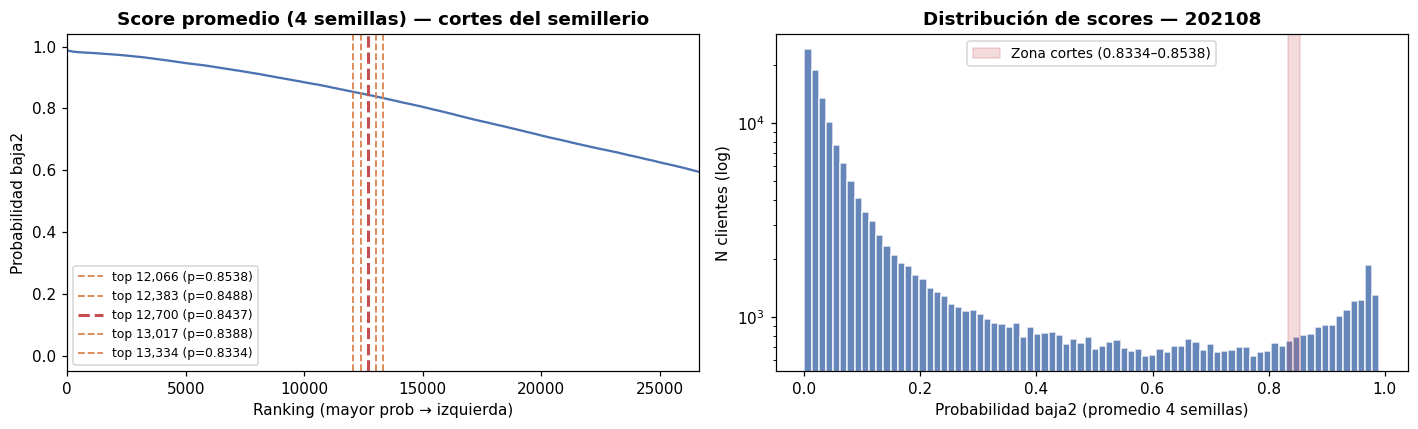

Thresholds de probabilidad para cada corte:
  top 12,066: prob >= 0.853833
  top 12,383: prob >= 0.848759
  top 12,700: prob >= 0.843703 ← centro
  top 13,017: prob >= 0.838812
  top 13,334: prob >= 0.833441


In [17]:
# Gráfico de scores del semillerio (promedio) con los cortes marcados
prob_prom = np.mean(probs_semillerio, axis=0)
scores_sorted = np.sort(prob_prom)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Ganancia estimada vs N intervenidos
# (aproximada — no tenemos el target real de 202108)
# Mostramos la distribución de scores y los cortes
ax = axes[0]
ax.plot(np.arange(1, len(scores_sorted)+1), scores_sorted,
        color='#4C72B0', lw=1.5)
for i, n in enumerate(CORTES_N):
    thresh = float(scores_sorted[n-1])
    color  = '#C44E52' if n == N_OPT_CENTRO else '#DD8452'
    lw     = 2.0 if n == N_OPT_CENTRO else 1.2
    ax.axvline(n, color=color, ls='--', lw=lw,
               label=f'top {n:,} (p={thresh:.4f})')
ax.set_title('Score promedio (4 semillas) — cortes del semillerio', fontweight='bold')
ax.set_xlabel('Ranking (mayor prob → izquierda)')
ax.set_ylabel('Probabilidad baja2')
ax.set_xlim(0, max(CORTES_N) * 2)
ax.legend(fontsize=8)

# Distribución de scores
ax = axes[1]
ax.hist(prob_prom, bins=80, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.set_yscale('log')
umbral_min = float(scores_sorted[max(CORTES_N)-1])
umbral_max = float(scores_sorted[min(CORTES_N)-1])
ax.axvspan(umbral_min, umbral_max, alpha=0.2, color='#C44E52',
           label=f'Zona cortes ({umbral_min:.4f}–{umbral_max:.4f})')
ax.set_title('Distribución de scores — 202108', fontweight='bold')
ax.set_xlabel('Probabilidad baja2 (promedio 4 semillas)')
ax.set_ylabel('N clientes (log)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

print('Thresholds de probabilidad para cada corte:')
for n in CORTES_N:
    t = float(scores_sorted[n-1])
    centro = ' ← centro' if n == N_OPT_CENTRO else ''
    print(f'  top {n:>6,}: prob >= {t:.6f}{centro}')

In [18]:
# Generación de archivos
archivos_generados = []
print(f'Generando archivos en: {RUTA_SUBS}')

for i_sem, semilla in enumerate(SEMILLAS):
    prob_s = probs_semillerio[i_sem]
    for n_corte in CORTES_N:
        ranking      = np.argsort(prob_s)[::-1][:n_corte]
        ids_intervenir = ids_pred[ranking].astype(int)
        nombre       = f'v4{EXP_GANADOR}_sem{semilla}_top{n_corte}_{TS}'
        ruta         = RUTA_SUBS / f'{nombre}.csv'
        pd.Series(ids_intervenir).to_csv(ruta, index=False, header=False)
        archivos_generados.append({'nombre': nombre, 'semilla': semilla,
                                   'n_corte': n_corte, 'n_clientes': len(ids_intervenir)})
        print(f'  ✓ {nombre}.csv')

# Log
df_arch = pd.DataFrame(archivos_generados)
df_arch.to_csv(RUTA_SUBS / f'log_{TS}.csv', index=False)
print(f'\nTotal archivos: {len(archivos_generados)} — listos para subir')

Generando archivos en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions1
  ✓ v4B_sem42_top12066_1006_0325.csv
  ✓ v4B_sem42_top12383_1006_0325.csv
  ✓ v4B_sem42_top12700_1006_0325.csv
  ✓ v4B_sem42_top13017_1006_0325.csv
  ✓ v4B_sem42_top13334_1006_0325.csv
  ✓ v4B_sem123_top12066_1006_0325.csv
  ✓ v4B_sem123_top12383_1006_0325.csv
  ✓ v4B_sem123_top12700_1006_0325.csv
  ✓ v4B_sem123_top13017_1006_0325.csv
  ✓ v4B_sem123_top13334_1006_0325.csv
  ✓ v4B_sem777_top12066_1006_0325.csv
  ✓ v4B_sem777_top12383_1006_0325.csv
  ✓ v4B_sem777_top12700_1006_0325.csv
  ✓ v4B_sem777_top13017_1006_0325.csv
  ✓ v4B_sem777_top13334_1006_0325.csv
  ✓ v4B_sem2024_top12066_1006_0325.csv
  ✓ v4B_sem2024_top12383_1006_0325.csv
  ✓ v4B_sem2024_top12700_1006_0325.csv
  ✓ v4B_sem2024_top13017_1006_0325.csv
  ✓ v4B_sem2024_top13334_1006_0325.csv

Total archivos: 20 — listos para subir


In [19]:
# Verificación de formato
ruta_check = RUTA_SUBS / f'{archivos_generados[0]["nombre"]}.csv'
with open(ruta_check) as f:
    lineas = [f.readline().strip() for _ in range(5)]
print(f'Verificación de {ruta_check.name}:')
print(f'  Primeras 5 líneas: {lineas}')
df_v = pd.read_csv(ruta_check, header=None)
tiene_e = df_v[0].astype(str).str.lower().str.contains('e').any()
print(f'  Sin notación científica: {"✓" if not tiene_e else "✗ PROBLEMA"}')
print(f'  N filas: {len(df_v):,}')

# Instrucciones
nombre_submit = f'v4{EXP_GANADOR}_semillerio_{TS}'
print(f'\n{"="*55}')
print('SUBMIT EN ZULIP')
print(f'{"="*55}')
print(f'Cuerpo: submit {nombre_submit}')
print(f'Adjuntos: los {len(archivos_generados)} archivos .csv de {RUTA_SUBS.name}/')
print(f'\nExp {EXP_GANADOR} | Centro: {N_OPT_CENTRO:,} clientes | Cortes: {CORTES_N}')

del df; gc.collect()
print('\n✓ Notebook v4 completada.')

Verificación de v4B_sem42_top12066_1006_0325.csv:
  Primeras 5 líneas: ['44098430', '70417732', '65536864', '70465889', '46108263']
  Sin notación científica: ✓
  N filas: 12,066

SUBMIT EN ZULIP
Cuerpo: submit v4B_semillerio_1006_0325
Adjuntos: los 20 archivos .csv de submissions1/

Exp B | Centro: 12,700 clientes | Cortes: [12066, 12383, 12700, 13017, 13334]

✓ Notebook v4 completada.
